# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Zahra Aulia Rahmani
- **Email:** zahralr06@gmail.com
- **ID Dicoding:** DS156B6X1810

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa selisih rata-rata jumlah penyewaan sepeda per hari antara **hari kerja** dan **hari libur** (akhir pekan + libur nasional) untuk pengguna *casual* dan *registered* sepanjang **2011–2012**, serta pada jam berapa puncak penyewaan terjadi pada masing-masing jenis pengguna?
- **Pertanyaan 2:** Pada **kategori suhu** (dingin, sejuk, hangat, panas) dan **kondisi cuaca** apa rata-rata penyewaan sepeda harian paling tinggi selama **2011–2012**, dan berapa persen penurunannya saat hujan/salju ringan dibandingkan cuaca cerah?

**Penerapan SMART:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Fokus pada hari kerja vs hari libur dan jenis pengguna casual vs registered | Fokus pada kategori suhu dan kondisi cuaca terhadap penyewaan harian |
| Measurable | Selisih rata-rata penyewaan per hari (jumlah & %) dan jam puncak | Rata-rata penyewaan per kategori dan persentase penurunan vs cuaca cerah |
| Action-oriented | Menentukan alokasi & penjadwalan sepeda per jam serta promo per jenis pengguna | Menentukan strategi stok, perawatan, dan promosi berdasarkan kondisi suhu/cuaca |
| Relevant | Efisiensi operasional dan pendapatan sistem bike sharing | Prediksi permintaan dan perencanaan armada |
| Time-bound | Januari 2011 – Desember 2012 | Januari 2011 – Desember 2012 |

## Import Semua Packages/Library yang Digunakan

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid.axis'] = 'y'
plt.rcParams['axes.titleweight'] = 'bold'

COLOR_CASUAL = '#E69F00'
COLOR_REGISTERED = '#0072B2'
COLOR_HIGHLIGHT = '#D55E00'
COLOR_NEUTRAL = '#B8B8B8'

## Data Wrangling

### Gathering Data

#### Load df day
Dataset yang digunakan adalah **Bike Sharing Dataset** (Capital Bikeshare, Washington D.C., 2011–2012) yang terdiri dari dua tabel: `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam).

*Sitasi: Fanaee-T, H. & Gama, J. (2013). Event labeling combining ensemble detectors and background knowledge. Progress in Artificial Intelligence, 1–15. doi:10.1007/s13748-013-0040-3.*

Memuat `day.csv` (agregasi penyewaan per hari) ke dalam DataFrame `day_df`.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Memuat data harian (day.csv) ke dalam DataFrame day_df

# Folder 'data' di Google Gdrive
DATA_DIR = '/content/drive/MyDrive/submissionfinal/data/'

# Baca file csv lalu tampilkan 5 baris pertama
day_df = pd.read_csv(f'{DATA_DIR}/day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load df hour
Memuat `hour.csv` (agregasi penyewaan per jam) ke dalam DataFrame `hour_df`.

In [7]:
# Memuat data per jam (hour.csv) ke dalam DataFrame hour_df

# Baca file csv lalu tampilkan 5 baris pertama
hour_df = pd.read_csv(f'{DATA_DIR}/hour.csv')
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris dan 16 kolom (data harian 1 Januari 2011 – 31 Desember 2012), sedangkan `hour_df` berisi 17,379 baris dan 17 kolom (ada tambahan kolom `hr` = jam 0–23).
- Keduanya memuat jumlah penyewaan (`casual`, `registered`, `cnt`) beserta informasi musim, hari kerja/libur, dan cuaca. `day_df` dipakai untuk membandingkan pola harian & pengaruh cuaca, sedangkan `hour_df` untuk melihat pola per jam.
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` masih dalam skala ternormalisasi (0–1), dan kolom kategori (`season`, `weathersit`, `weekday`, `yr`, `mnth`) masih berupa angka sehingga belum siap dibaca langsung.

### Assessing Data

#### Identifying data type problem
Memeriksa jumlah baris, kolom, dan kesesuaian tipe data setiap kolom.

In [8]:
# Meninjau jumlah baris, kolom, dan tipe data pada day_df dengan info

day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [9]:
# Meninjau jumlah baris, kolom, dan tipe data pada hour_df dengan info

hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


#### Identifying missing value and duplicate data problem
Memeriksa apakah ada nilai kosong atau baris yang sama persis.

In [10]:
# Mengecek missing value pada day_df menggunakan isnull().sum()

day_df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [11]:
# Mengecek missing value pada hour_df menggunakan isnull().sum()

hour_df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [12]:
# Mengecek data duplikat pada day_df menggunakan duplicated().sum()

day_df.duplicated().sum()

np.int64(0)

In [13]:
# Mengecek data duplikat pada hour_df menggunakan duplicated().sum()

hour_df.duplicated().sum()

np.int64(0)

#### Identifying invalid value problem
Memeriksa nilai yang tidak masuk akal secara fisik, misalnya kelembapan udara 0%.

In [14]:
# Menampilkan statistik deskriptif kolom numerik pada day_df dengan describe
# Tujuannya melihat rentang nilai yang tidak wajar (misalnya hum dengan nilai minimum 0)

day_df[['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe()

,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [15]:
# Memeriksa baris pada day_df yang kelembapannya (hum) bernilai 0

day_df[day_df['hum'] == 0][['dteday', 'temp', 'hum', 'windspeed', 'cnt']]

,dteday,temp,hum,windspeed,cnt
68,2011-03-10,0.389091,0.0,0.261877,623


In [16]:
# Memeriksa tanggal pada hour_df yang kelembapannya (hum) bernilai 0

hour_df[hour_df['hum'] == 0]['dteday'].value_counts()

,count
dteday,
2011-03-10,22


#### Identifying inconsistent data problem
Memeriksa apakah kolom-kolom yang saling berkaitan masih konsisten satu sama lain.

In [17]:
# Memeriksa konsistensi: cnt seharusnya sama dengan casual + registered

# Hitung jumlah baris yang tidak konsisten pada day_df dan hour_df
print('day_df  :', (day_df['cnt'] != day_df['casual'] + day_df['registered']).sum())
print('hour_df :', (hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum())

day_df  : 0
hour_df : 0


In [18]:
# Memeriksa konsistensi workingday dengan weekday dan holiday pada day_df

# Hari non-kerja = akhir pekan (weekday 0 = Minggu, 6 = Sabtu) atau holiday = 1
non_working = day_df['weekday'].isin([0, 6]) | (day_df['holiday'] == 1)

# Hitung jumlah baris yang workingday-nya tidak sesuai aturan di atas
(day_df['workingday'] != (~non_working).astype(int)).sum()

np.int64(0)

#### Identifying incomplete hourly data problem
Memeriksa apakah setiap hari pada `hour_df` memiliki 24 baris (jam 0–23).

In [19]:
# Memeriksa kelengkapan jam pada hour_df
# Seharusnya ada 731 hari x 24 jam = 17544 baris

# Hitung jumlah baris yang diharapkan
expected_rows = day_df.shape[0] * 24

print('Baris yang diharapkan :', expected_rows)
print('Baris aktual hour_df  :', hour_df.shape[0])
print('Jam tidak tercatat    :', expected_rows - hour_df.shape[0])

Baris yang diharapkan : 17544
Baris aktual hour_df  : 17379
Jam tidak tercatat    : 165


In [20]:
# Mencari jam (hr) yang paling sering tidak tercatat pada hour_df

# Buat index lengkap berisi semua kombinasi tanggal dan jam (0-23)
full_index = pd.MultiIndex.from_product(
    [pd.to_datetime(day_df['dteday']), range(24)],
    names=['dteday', 'hr']
)

# Buat index dari kombinasi tanggal dan jam yang benar-benar tercatat
recorded_index = pd.MultiIndex.from_arrays(
    [pd.to_datetime(hour_df['dteday']), hour_df['hr']],
    names=['dteday', 'hr']
)

# Ambil kombinasi yang tidak tercatat, lalu hitung jumlahnya untuk setiap jam
missing_hours = full_index.difference(recorded_index)
missing_by_hour = missing_hours.get_level_values('hr').value_counts().sort_index()
missing_by_hour

,count
hr,
0,5
1,7
2,16
3,34
4,34
5,14
6,6
7,4
8,4


#### Identifying outlier problem
Memeriksa nilai ekstrem dengan aturan IQR dan boxplot.

In [21]:
# Menghitung jumlah outlier dengan aturan IQR (1.5 x IQR) pada day_df dan hour_df

# Buat tabel kosong untuk menyimpan hasil
outlier_summary = pd.DataFrame(
    0,
    index=['casual', 'registered', 'cnt', 'hum', 'windspeed'],
    columns=['outlier_day_df', 'outlier_hour_df']
)

# Hitung outlier untuk setiap kolom pada kedua DataFrame
for col in outlier_summary.index:
    for nama_kolom, data in [('outlier_day_df', day_df), ('outlier_hour_df', hour_df)]:
        # Hitung kuartil 1, kuartil 3, dan IQR
        q1 = data[col].quantile(0.25)
        q3 = data[col].quantile(0.75)
        iqr = q3 - q1

        # Hitung data yang berada di luar batas bawah atau batas atas
        outlier_summary.loc[col, nama_kolom] = ((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum()

outlier_summary

,outlier_day_df,outlier_hour_df
casual,44,1192
registered,0,680
cnt,0,505
hum,2,22
windspeed,13,342


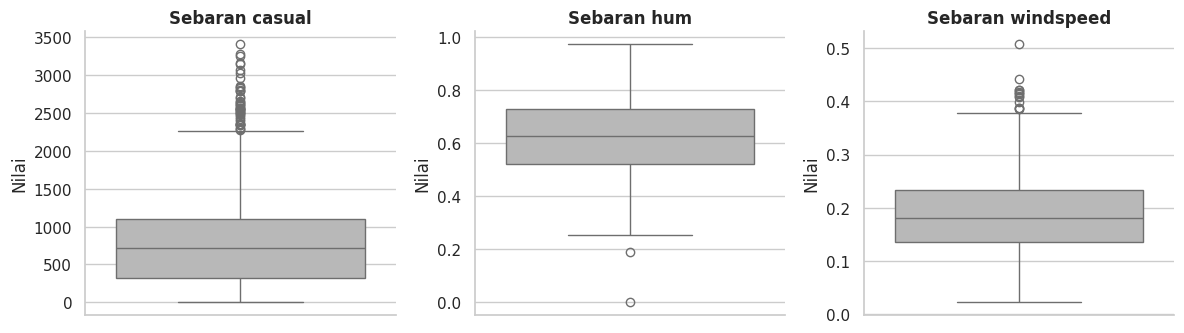

In [22]:
# Menampilkan boxplot untuk melihat outlier pada day_df

plt.figure(figsize=(12, 3.5))

# Buat satu boxplot untuk setiap kolom yang memiliki outlier
for i, col in enumerate(['casual', 'hum', 'windspeed']):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=day_df[col], color=COLOR_NEUTRAL)
    plt.title(f'Sebaran {col}')
    plt.ylabel('Nilai')

plt.tight_layout()
plt.show()

**Steps to Take:**
- **Tipe data tidak sesuai** — `dteday` bertipe teks (string). Ubah ke `datetime`.
- **Invalid value** — kelembapan (`hum`) bernilai 0 pada 1 hari di `day_df` (22 baris di `hour_df`), seluruhnya pada tanggal 2011-03-10. Kelembapan 0% tidak masuk akal, sehingga dianggap data hilang: ganti dengan NaN lalu isi dengan interpolasi linear.
- **Nilai ternormalisasi** — `temp`, `atemp`, `hum`, `windspeed` dikembalikan ke skala asli (dikali 41, 50, 100, dan 67 sesuai dokumentasi) agar bisa dipakai untuk binning suhu.
- **Kolom kategori berupa angka** — `season`, `weathersit`, `weekday`, `yr`, `mnth`, dan `workingday` dipetakan ke label yang mudah dibaca.
- **Data tidak lengkap pada `hour_df`** — 165 jam tidak tercatat (dari 17,544 jam yang seharusnya), 98 di antaranya (59%) terjadi pada pukul 02:00–05:00. Jam tanpa catatan berarti tidak ada penyewaan, sehingga dilengkapi dengan nilai 0 agar rata-rata per jam tidak bias ke atas.
- **Outlier** — `casual` memiliki 44 outlier dan `windspeed` 13 outlier pada `day_df`. Outlier diperiksa lebih lanjut pada tahap cleaning; keputusan: dipertahankan jika terbukti merupakan kejadian nyata.

**Insight:**
- Secara struktur data sudah baik: tidak ada missing value dan tidak ada data duplikat. Data juga konsisten (`cnt` = `casual` + `registered` pada seluruh baris, dan `workingday` sesuai dengan `weekday` & `holiday`).
- Meski demikian ditemukan masalah kualitas yang tersembunyi: tipe data tanggal, invalid value pada `hum`, skala data ternormalisasi, kolom kategori berupa angka, dan jam yang tidak tercatat pada `hour_df`.
- Jam yang hilang paling banyak terjadi pada dini hari (pukul 02:00–05:00) saat penyewaan sangat sepi. Jika dibiarkan, rata-rata penyewaan per jam pada dini hari akan terlihat lebih tinggi dari kenyataan.

### Cleaning Data

#### Fixing data type problem
Mengubah kolom `dteday` dari teks menjadi `datetime`.

In [23]:
# Mengubah tipe data dteday menjadi datetime pada day_df dan hour_df

day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# Cek kembali tipe data dan rentang tanggalnya
print('Tipe dteday day_df  :', day_df['dteday'].dtype)
print('Tipe dteday hour_df :', hour_df['dteday'].dtype)
print('Rentang tanggal     :', day_df['dteday'].min().date(), 's.d.', day_df['dteday'].max().date())

Tipe dteday day_df  : datetime64[ns]
Tipe dteday hour_df : datetime64[ns]
Rentang tanggal     : 2011-01-01 s.d. 2012-12-31


#### Fixing invalid value problem
Mengganti kelembapan 0% (data yang hilang) dengan nilai hasil interpolasi.

In [24]:
# Menangani hum = 0 pada day_df

# Urutkan data berdasarkan tanggal agar interpolasi berjalan benar
day_df = day_df.sort_values('dteday').reset_index(drop=True)

# Ganti nilai 0 dengan NaN, lalu isi dengan interpolasi linear antar-tanggal
day_df['hum'] = day_df['hum'].replace(0, np.nan).interpolate(method='linear')

# Cek kembali jumlah hum yang bernilai 0 atau kosong
print('hum = 0    :', (day_df['hum'] == 0).sum())
print('hum kosong :', day_df['hum'].isnull().sum())

hum = 0    : 0
hum kosong : 0


In [25]:
# Menangani hum = 0 pada hour_df memakai nilai kelembapan harian yang sudah bersih

# Ambil nilai hum harian dari day_df (indeks = tanggal)
hum_daily = day_df.set_index('dteday')['hum']

# Pilih baris yang hum-nya 0, lalu isi dengan hum harian pada tanggal yang sama
zero_hum = hour_df['hum'] == 0
hour_df.loc[zero_hum, 'hum'] = hour_df.loc[zero_hum, 'dteday'].map(hum_daily)

# Cek kembali jumlah hum yang bernilai 0 atau kosong
print('hum = 0    :', (hour_df['hum'] == 0).sum())
print('hum kosong :', hour_df['hum'].isnull().sum())

hum = 0    : 0
hum kosong : 0


#### Fixing normalized scale and categorical code problem
Mengembalikan nilai ke skala asli dan mengganti kode angka dengan label yang mudah dibaca.

In [26]:
# Mengembalikan kolom ternormalisasi ke skala asli pada day_df

day_df['temp_c'] = day_df['temp'] * 41         # suhu (derajat Celsius)
day_df['atemp_c'] = day_df['atemp'] * 50       # suhu terasa (derajat Celsius)
day_df['hum_pct'] = day_df['hum'] * 100        # kelembapan (%)
day_df['wind_speed'] = day_df['windspeed'] * 67   # kecepatan angin (satuan asli dataset)

# Cek hasil konversi suhu dan kelembapan
day_df[['temp', 'temp_c', 'hum', 'hum_pct']].head()

,temp,temp_c,hum,hum_pct
0,0.344167,14.110847,0.805833,80.5833
1,0.363478,14.902598,0.696087,69.6087
2,0.196364,8.050924,0.437273,43.7273
3,0.200000,8.200000,0.590435,59.0435
4,0.226957,9.305237,0.436957,43.6957


In [27]:
# Mengubah kolom kategori yang berupa angka menjadi label pada day_df

# Buat dictionary untuk memetakan kode angka ke label
season_map = {1: 'Musim Semi', 2: 'Musim Panas', 3: 'Musim Gugur', 4: 'Musim Dingin'}
weather_map = {1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan', 4: 'Hujan/Salju Lebat'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
day_type_map = {1: 'Hari Kerja', 0: 'Hari Libur'}   # Hari Libur = akhir pekan + libur nasional

# Terapkan mapping ke kolom yang sesuai
day_df['season'] = day_df['season'].map(season_map)
day_df['year'] = day_df['yr'].map({0: 2011, 1: 2012})
day_df['month'] = day_df['mnth']
day_df['weekday'] = day_df['weekday'].map(weekday_map)
day_df['weather'] = day_df['weathersit'].map(weather_map)
day_df['day_type'] = day_df['workingday'].map(day_type_map)

# Cek hasil mapping
day_df[['dteday', 'season', 'weekday', 'weather', 'day_type']].head()

,dteday,season,weekday,weather,day_type
0,2011-01-01,Musim Semi,Sabtu,Berkabut/Berawan,Hari Libur
1,2011-01-02,Musim Semi,Minggu,Berkabut/Berawan,Hari Libur
2,2011-01-03,Musim Semi,Senin,Cerah,Hari Kerja
3,2011-01-04,Musim Semi,Selasa,Cerah,Hari Kerja
4,2011-01-05,Musim Semi,Rabu,Cerah,Hari Kerja


In [28]:
# Memilih kolom yang dipakai pada day_df (kolom lama yang sudah diganti tidak dipakai lagi)

day_df = day_df[[
    'dteday', 'year', 'month', 'season', 'weekday', 'holiday', 'workingday', 'day_type',
    'weather', 'temp_c', 'atemp_c', 'hum_pct', 'wind_speed', 'casual', 'registered', 'cnt'
]]

# Tampilkan 5 baris pertama untuk memverifikasi
day_df.head()

,dteday,year,month,season,weekday,holiday,workingday,day_type,weather,temp_c,atemp_c,hum_pct,wind_speed,casual,registered,cnt
0,2011-01-01,2011,1,Musim Semi,Sabtu,0,0,Hari Libur,Berkabut/Berawan,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2011-01-02,2011,1,Musim Semi,Minggu,0,0,Hari Libur,Berkabut/Berawan,14.902598,17.68695,69.6087,16.652113,131,670,801
2,2011-01-03,2011,1,Musim Semi,Senin,0,1,Hari Kerja,Cerah,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,2011-01-04,2011,1,Musim Semi,Selasa,0,1,Hari Kerja,Cerah,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,2011-01-05,2011,1,Musim Semi,Rabu,0,1,Hari Kerja,Cerah,9.305237,11.46350,43.6957,12.522300,82,1518,1600


#### Fixing incomplete hourly data problem
Melengkapi jam yang tidak tercatat pada `hour_df` dengan jumlah penyewaan 0.

In [29]:
# Mempersiapkan hour_df: kembalikan skala asli dan ubah kode cuaca menjadi label

# Pilih kolom yang bersifat per jam saja (atribut tingkat-hari akan diambil dari day_df)
hour_core = hour_df[['dteday', 'hr', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
                     'casual', 'registered', 'cnt']].copy()

# Kembalikan kolom ternormalisasi ke skala asli
hour_core['temp_c'] = hour_core['temp'] * 41
hour_core['atemp_c'] = hour_core['atemp'] * 50
hour_core['hum_pct'] = hour_core['hum'] * 100
hour_core['wind_speed'] = hour_core['windspeed'] * 67

# Ubah kode cuaca menjadi label, lalu hapus kolom lama
hour_core['weather'] = hour_core['weathersit'].map(weather_map)
hour_core = hour_core.drop(columns=['weathersit', 'temp', 'atemp', 'hum', 'windspeed'])

# Tampilkan 5 baris pertama untuk memverifikasi
hour_core.head()

,dteday,hr,casual,registered,cnt,temp_c,atemp_c,hum_pct,wind_speed,weather
0,2011-01-01,0,3,13,16,9.84,14.395,81.0,0.0,Cerah
1,2011-01-01,1,8,32,40,9.02,13.635,80.0,0.0,Cerah
2,2011-01-01,2,5,27,32,9.02,13.635,80.0,0.0,Cerah
3,2011-01-01,3,3,10,13,9.84,14.395,75.0,0.0,Cerah
4,2011-01-01,4,0,1,1,9.84,14.395,75.0,0.0,Cerah


In [30]:
# Melengkapi 165 jam yang tidak tercatat pada hour_df
# Jam yang tidak tercatat berarti tidak ada penyewaan, sehingga jumlah penyewaannya diisi 0

# Buat index lengkap berisi semua kombinasi tanggal dan jam (0-23)
full_index = pd.MultiIndex.from_product([day_df['dteday'], range(24)], names=['dteday', 'hr'])

# Samakan hour_core dengan index lengkap (jam yang hilang akan terisi NaN)
hour_full = hour_core.set_index(['dteday', 'hr']).reindex(full_index).reset_index()

# Beri penanda baris hasil pelengkapan sebelum NaN diisi
hour_full['is_filled'] = hour_full['cnt'].isnull()

# Isi jumlah penyewaan yang kosong dengan 0
for col in ['casual', 'registered', 'cnt']:
    hour_full[col] = hour_full[col].fillna(0).astype(int)

# Cek jumlah baris dan jumlah baris hasil pelengkapan
print('Jumlah baris           :', hour_full.shape[0], '(731 x 24 =', 731 * 24, ')')
print('Baris hasil dilengkapi :', hour_full['is_filled'].sum())

Jumlah baris           : 17544 (731 x 24 = 17544 )
Baris hasil dilengkapi : 165


In [31]:
# Menambahkan atribut tingkat-hari (musim, tipe hari, dll.) pada hour_df dari day_df yang sudah bersih

# Ambil kolom atribut harian dari day_df
day_info = day_df[['dteday', 'year', 'month', 'season', 'weekday', 'holiday', 'workingday', 'day_type']]

# Gabungkan berdasarkan tanggal, lalu ganti nama kolom hr menjadi hour
hour_df = hour_full.merge(day_info, on='dteday', how='left').rename(columns={'hr': 'hour'})

# Pilih dan urutkan kolom
hour_df = hour_df[[
    'dteday', 'hour', 'year', 'month', 'season', 'weekday', 'holiday', 'workingday', 'day_type',
    'weather', 'temp_c', 'atemp_c', 'hum_pct', 'wind_speed', 'casual', 'registered', 'cnt', 'is_filled'
]]

# Verifikasi: cnt harus tetap sama dengan casual + registered
print('cnt = casual + registered :', (hour_df['cnt'] == hour_df['casual'] + hour_df['registered']).all())
hour_df.head()

cnt = casual + registered : True


,dteday,hour,year,month,season,weekday,holiday,workingday,day_type,weather,temp_c,atemp_c,hum_pct,wind_speed,casual,registered,cnt,is_filled
0,2011-01-01,0,2011,1,Musim Semi,Sabtu,0,0,Hari Libur,Cerah,9.84,14.395,81.0,0.0,3,13,16,False
1,2011-01-01,1,2011,1,Musim Semi,Sabtu,0,0,Hari Libur,Cerah,9.02,13.635,80.0,0.0,8,32,40,False
2,2011-01-01,2,2011,1,Musim Semi,Sabtu,0,0,Hari Libur,Cerah,9.02,13.635,80.0,0.0,5,27,32,False
3,2011-01-01,3,2011,1,Musim Semi,Sabtu,0,0,Hari Libur,Cerah,9.84,14.395,75.0,0.0,3,10,13,False
4,2011-01-01,4,2011,1,Musim Semi,Sabtu,0,0,Hari Libur,Cerah,9.84,14.395,75.0,0.0,0,1,1,False


#### Handling outlier problem
Memeriksa apakah outlier merupakan kejadian nyata sebelum memutuskan dipertahankan atau dihapus.

In [32]:
# Memeriksa outlier casual: apakah kejadian nyata atau kesalahan data?
# Tampilkan 5 hari dengan pengguna casual tertinggi

day_df.nlargest(5, 'casual')[['dteday', 'weekday', 'day_type', 'weather', 'temp_c', 'casual', 'cnt']]

,dteday,weekday,day_type,weather,temp_c,casual,cnt
504,2012-05-19,Sabtu,Hari Libur,Cerah,24.600000,3410,8294
512,2012-05-27,Minggu,Hari Libur,Cerah,28.290000,3283,6591
462,2012-04-07,Sabtu,Hari Libur,Cerah,17.937500,3252,6857
623,2012-09-15,Sabtu,Hari Libur,Cerah,24.941653,3160,8714
441,2012-03-17,Sabtu,Hari Libur,Berkabut/Berawan,21.080847,3155,7836


In [33]:
# Mengecek day_df setelah pembersihan dengan info

day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      731 non-null    datetime64[ns]
 1   year        731 non-null    int64         
 2   month       731 non-null    int64         
 3   season      731 non-null    object        
 4   weekday     731 non-null    object        
 5   holiday     731 non-null    int64         
 6   workingday  731 non-null    int64         
 7   day_type    731 non-null    object        
 8   weather     731 non-null    object        
 9   temp_c      731 non-null    float64       
 10  atemp_c     731 non-null    float64       
 11  hum_pct     731 non-null    float64       
 12  wind_speed  731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

**Insight:**
- `day_df` bersih berisi 731 baris × 16 kolom dan `hour_df` bersih berisi 17,544 baris (= 731 hari × 24 jam), termasuk 165 baris yang dilengkapi dengan penyewaan 0 (ditandai kolom `is_filled`).
- Kelembapan 2011-03-10 yang semula 0 kini bernilai 71.2% (hasil interpolasi hari sebelum dan sesudahnya).
- Outlier **dipertahankan**: lima hari dengan pengguna *casual* tertinggi seluruhnya jatuh pada akhir pekan dengan cuaca cerah atau berkabut tipis. Ini adalah pola perilaku yang nyata (rekreasi akhir pekan), bukan kesalahan pencatatan, dan justru relevan untuk menjawab Pertanyaan 1.
- Kolom asli yang ternormalisasi diganti dengan `temp_c`, `atemp_c`, `hum_pct`, dan `wind_speed` (skala asli). Satuan `wind_speed` mengikuti skala asli dataset (tidak dijelaskan di dokumentasi), sehingga hanya digunakan untuk perbandingan relatif.

## Exploratory Data Analysis (EDA)

### Explore `day_df`: ringkasan statistik dan tren tahunan

In [34]:
# Menampilkan statistik deskriptif day_df yang sudah bersih dengan describe

day_df[['temp_c', 'hum_pct', 'wind_speed', 'casual', 'registered', 'cnt']].describe()

,temp_c,hum_pct,wind_speed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,20.310776,62.886874,12.762576,848.176471,3656.172367,4504.348837
std,7.505091,14.055188,5.192357,686.622488,1560.256377,1937.211452
min,2.424346,18.791700,1.500244,2.000000,20.000000,22.000000
25%,13.820424,52.104150,9.041650,315.500000,2497.000000,3152.000000
50%,20.431653,62.750000,12.125325,713.000000,3662.000000,4548.000000
75%,26.872076,73.020850,15.625371,1096.000000,4776.500000,5956.000000
max,35.328347,97.250000,34.000021,3410.000000,6946.000000,8714.000000


In [35]:
# Menghitung total dan rata-rata penyewaan per tahun beserta pertumbuhannya

yearly = day_df.groupby('year')['cnt'].agg(total='sum', rata2_per_hari='mean')

# Hitung persentase pertumbuhan dibanding tahun sebelumnya
yearly['pertumbuhan_vs_tahun_sebelumnya_%'] = yearly['total'].pct_change() * 100
yearly.round(1)

,total,rata2_per_hari,pertumbuhan_vs_tahun_sebelumnya_%
year,,,
2011,1243103,3405.8,NaN
2012,2049576,5599.9,64.9


In [36]:
# Menghitung jumlah hari pada setiap tipe hari

day_df['day_type'].value_counts()

,count
day_type,
Hari Kerja,500
Hari Libur,231


### Explore Pertanyaan 1: hari kerja vs hari libur

In [37]:
# Pertanyaan 1: menghitung rata-rata penyewaan HARIAN berdasarkan tipe hari

q1_daily = day_df.groupby('day_type')[['casual', 'registered', 'cnt']].mean()
q1_daily

,casual,registered,cnt
day_type,,,
Hari Kerja,606.570000,3978.250000,4584.820000
Hari Libur,1371.134199,2959.034632,4330.168831


In [38]:
# Pertanyaan 1: menghitung selisih rata-rata (Hari Libur - Hari Kerja) beserta persentasenya

# Putar tabel agar baris = jenis pengguna dan kolom = tipe hari
q1_summary = q1_daily.T

# Hitung selisih dan persentase perubahan terhadap hari kerja
q1_summary['Selisih (Libur - Kerja)'] = q1_summary['Hari Libur'] - q1_summary['Hari Kerja']
q1_summary['Selisih (%)'] = q1_summary['Selisih (Libur - Kerja)'] / q1_summary['Hari Kerja'] * 100
q1_summary.round(1)

day_type,Hari Kerja,Hari Libur,Selisih (Libur - Kerja),Selisih (%)
casual,606.6,1371.1,764.6,126.0
registered,3978.2,2959.0,-1019.2,-25.6
cnt,4584.8,4330.2,-254.7,-5.6


In [39]:
# Pertanyaan 1: menghitung porsi pengguna casual terhadap total penyewaan (%)

casual_share = q1_daily['casual'] / q1_daily['cnt'] * 100
casual_share.round(1)

,0
day_type,
Hari Kerja,13.2
Hari Libur,31.7


In [40]:
# Pertanyaan 1: menghitung rata-rata penyewaan PER JAM berdasarkan tipe hari

q1_hourly = hour_df.groupby(['day_type', 'hour'])[['casual', 'registered', 'cnt']].mean().reset_index()
q1_hourly.head()

,day_type,hour,casual,registered,cnt
0,Hari Kerja,0,7.092,29.400,36.492
1,Hari Kerja,1,3.666,12.688,16.354
2,Hari Kerja,2,2.082,6.376,8.458
3,Hari Kerja,3,0.856,3.790,4.646
4,Hari Kerja,4,0.720,4.384,5.104


In [41]:
# Pertanyaan 1: mencari jam puncak penyewaan untuk setiap tipe hari dan jenis pengguna

peak_rows = []

for day_type in ['Hari Kerja', 'Hari Libur']:
    # Ambil data rata-rata per jam pada tipe hari tersebut
    subset = q1_hourly[q1_hourly['day_type'] == day_type]

    for user in ['casual', 'registered']:
        # Cari baris dengan rata-rata penyewaan tertinggi
        top = subset.loc[subset[user].idxmax()]

        # Simpan jam puncak, nilainya, dan 3 jam tertinggi
        peak_rows.append({
            'day_type': day_type,
            'user': user,
            'jam_puncak': int(top['hour']),
            'rata2_per_jam': float(top[user]),
            'top3_jam': subset.nlargest(3, user)['hour'].astype(int).tolist()
        })

peak_hours = pd.DataFrame(peak_rows)
peak_hours.round({'rata2_per_jam': 1})

,day_type,user,jam_puncak,rata2_per_jam,top3_jam
0,Hari Kerja,casual,17,56.8,"[17, 18, 16]"
1,Hari Kerja,registered,17,467.5,"[17, 8, 18]"
2,Hari Libur,casual,14,139.6,"[14, 15, 13]"
3,Hari Libur,registered,12,240.0,"[12, 13, 14]"


### Explore Pertanyaan 2: suhu dan cuaca
Pada tahap ini diterapkan teknik **Binning** (`pd.cut`) untuk mengelompokkan suhu harian (°C) ke dalam 4 kategori: Dingin (<10°C), Sejuk (10–20°C), Hangat (20–28°C), dan Panas (≥28°C). Tujuannya agar pengaruh suhu terhadap penyewaan lebih mudah dibandingkan antar-kelompok dan hasilnya langsung bisa dipakai tim operasional (bukan sekadar angka suhu kontinu).

In [42]:
# Binning suhu dengan pd.cut: kelompokkan suhu harian (°C) menjadi 4 kategori

# Tentukan batas suhu dan label untuk setiap kategori
temp_bins = [-np.inf, 10, 20, 28, np.inf]
temp_labels = ['Dingin (<10°C)', 'Sejuk (10–20°C)', 'Hangat (20–28°C)', 'Panas (≥28°C)']

# Buat kolom kategori suhu, lalu cek jumlah hari pada setiap kategori
day_df['temp_category'] = pd.cut(day_df['temp_c'], bins=temp_bins, labels=temp_labels, right=False)
day_df['temp_category'].value_counts().sort_index()

,count
temp_category,
Dingin (<10°C),60
Sejuk (10–20°C),299
Hangat (20–28°C),222
Panas (≥28°C),150


In [43]:
# Pertanyaan 2: menghitung rata-rata penyewaan harian berdasarkan kategori suhu

q2_temp = day_df.groupby('temp_category', observed=True)['cnt'].agg(
    jumlah_hari='count',
    rata2_penyewaan='mean'
)
q2_temp.round(0)

,jumlah_hari,rata2_penyewaan
temp_category,,
Dingin (<10°C),60,1678.0
Sejuk (10–20°C),299,3692.0
Hangat (20–28°C),222,5581.0
Panas (≥28°C),150,5661.0


In [44]:
# Pertanyaan 2: menghitung rata-rata penyewaan harian berdasarkan kondisi cuaca

# Urutan kondisi cuaca (hari dengan hujan/salju lebat tidak ada pada day_df)
weather_order = ['Cerah', 'Berkabut/Berawan', 'Hujan/Salju Ringan']

q2_weather = day_df.groupby('weather')['cnt'].agg(
    jumlah_hari='count',
    rata2_penyewaan='mean'
).reindex(weather_order)

# Hitung persentase perubahan dibanding cuaca cerah
baseline = q2_weather.loc['Cerah', 'rata2_penyewaan']
q2_weather['perubahan_vs_cerah_%'] = (q2_weather['rata2_penyewaan'] / baseline - 1) * 100
q2_weather.round(1)

,jumlah_hari,rata2_penyewaan,perubahan_vs_cerah_%
weather,,,
Cerah,463,4876.8,0.0
Berkabut/Berawan,247,4035.9,-17.2
Hujan/Salju Ringan,21,1803.3,-63.0


In [45]:
# Pertanyaan 2: menghitung rata-rata penyewaan untuk kombinasi kategori suhu x kondisi cuaca

# Rata-rata penyewaan harian
q2_cross = day_df.pivot_table(index='temp_category', columns='weather', values='cnt',
                              aggfunc='mean', observed=True).reindex(columns=weather_order)

# Jumlah hari pada setiap kombinasi (untuk melihat apakah datanya cukup)
q2_cross_n = day_df.pivot_table(index='temp_category', columns='weather', values='cnt',
                                aggfunc='count', observed=True).reindex(columns=weather_order)

q2_cross.round(0)

weather,Cerah,Berkabut/Berawan,Hujan/Salju Ringan
temp_category,,,
Dingin (<10°C),1758.0,1631.0,1039.0
Sejuk (10–20°C),4069.0,3336.0,1297.0
Hangat (20–28°C),6081.0,5035.0,2927.0
Panas (≥28°C),5686.0,5553.0,NaN


In [46]:
# Menghitung korelasi faktor cuaca dengan total penyewaan harian (cnt)

day_df[['cnt', 'temp_c', 'hum_pct', 'wind_speed']].corr()['cnt'].drop('cnt').round(2)

,cnt
temp_c,0.63
hum_pct,-0.12
wind_speed,-0.23


**Insight:**
- Total penyewaan 2012 (2,049,576) naik 64.9% dibanding 2011 (1,243,103), sehingga perbandingan antar-kelompok sebaiknya memakai rata-rata (bukan total).
- Secara total, rata-rata penyewaan harian pada hari kerja (4,585) hanya sedikit lebih tinggi dari hari libur (4,330; -5.6%). Namun komposisinya berbeda tajam: *casual* 607 → 1,371 (+126.0%), *registered* 3,978 → 2,959 (-25.6%). Porsi casual naik dari 13.2% menjadi 31.7% dari total.
- Jam puncak: *registered* di hari kerja pukul 17:00 (rata-rata 467 sepeda/jam; puncak lainnya pukul 08:00), *casual* di hari libur pukul 14:00 (140), dan *registered* di hari libur pukul 12:00 (240).
- Suhu berkorelasi positif dengan penyewaan (r = 0.63), sedangkan kecepatan angin berkorelasi negatif lemah (r = -0.23) dan kelembapan nyaris tidak berkorelasi (r = -0.12).
- Rata-rata penyewaan harian per kategori suhu: Dingin 1,678, Sejuk 3,692, Hangat 5,581, Panas 5,661. Menurut cuaca: Cerah 4,877, Berkabut/Berawan -17.2%, Hujan/Salju Ringan -63.0% dibanding cerah.
- Kombinasi tertinggi: **Hangat + Cerah** (6,081 sepeda/hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Hari kerja vs hari libur
*Berapa selisih rata-rata penyewaan per hari antara hari kerja dan hari libur untuk pengguna casual dan registered, dan pada jam berapa puncaknya?*

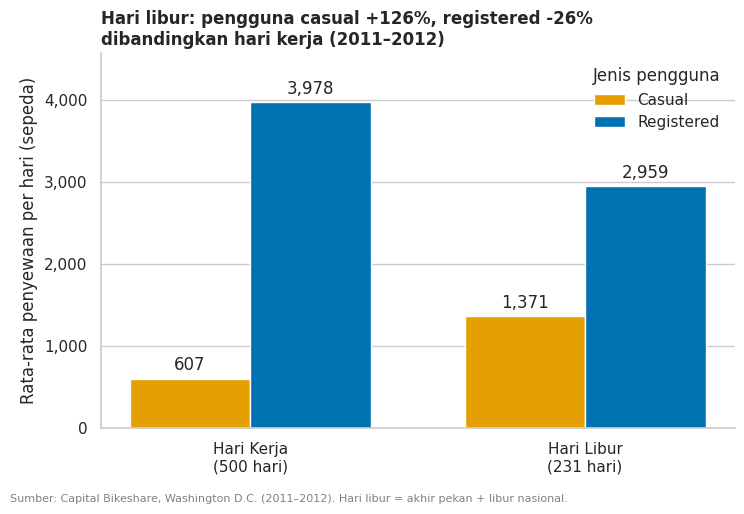

In [47]:
# Visualisasi 1: rata-rata penyewaan harian pada hari kerja vs hari libur untuk setiap jenis pengguna

# Siapkan data yang akan divisualisasikan
tipe_hari = ['Hari Kerja', 'Hari Libur']
casual_vals = q1_daily.loc[tipe_hari, 'casual']
registered_vals = q1_daily.loc[tipe_hari, 'registered']
jumlah_hari = day_df['day_type'].value_counts()

# Ambil persentase perubahan untuk judul grafik
pct_casual = q1_summary.loc['casual', 'Selisih (%)']
pct_registered = q1_summary.loc['registered', 'Selisih (%)']

# Buat bar chart berdampingan untuk casual dan registered
fig, ax = plt.subplots(figsize=(7.5, 5))
x = np.arange(len(tipe_hari))
bars_c = ax.bar(x - 0.18, casual_vals, width=0.36, color=COLOR_CASUAL, label='Casual')
bars_r = ax.bar(x + 0.18, registered_vals, width=0.36, color=COLOR_REGISTERED, label='Registered')

# Tampilkan nilai di atas setiap batang
ax.bar_label(bars_c, labels=[f'{v:,.0f}' for v in casual_vals], padding=3)
ax.bar_label(bars_r, labels=[f'{v:,.0f}' for v in registered_vals], padding=3)

# Atur judul, label sumbu, dan legend
ax.set_xticks(x)
ax.set_xticklabels([f'{t}\n({jumlah_hari[t]} hari)' for t in tipe_hari])
ax.set_ylim(0, registered_vals.max() * 1.15)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_ylabel('Rata-rata penyewaan per hari (sepeda)')
ax.set_title(f'Hari libur: pengguna casual {pct_casual:+.0f}%, registered {pct_registered:+.0f}%\n'
             'dibandingkan hari kerja (2011–2012)', loc='left')
ax.legend(title='Jenis pengguna', frameon=False)

# Tambahkan sumber data
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare, Washington D.C. (2011–2012). Hari libur = akhir pekan + libur nasional.',
         fontsize=8, color='gray')

plt.tight_layout()
plt.show()

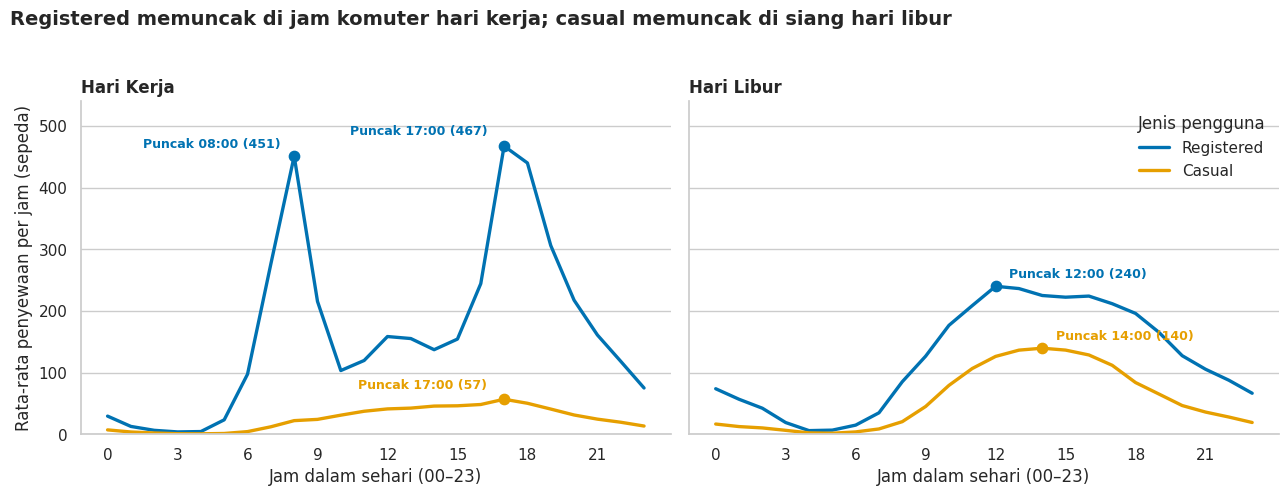

In [48]:
# Visualisasi 2: pola rata-rata penyewaan per jam pada hari kerja vs hari libur

# Buat 2 grafik berdampingan dengan sumbu-y yang sama agar mudah dibandingkan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, day_type in zip(axes, ['Hari Kerja', 'Hari Libur']):
    # Ambil data rata-rata per jam pada tipe hari tersebut
    sub = q1_hourly[q1_hourly['day_type'] == day_type]

    # Gambar garis untuk registered dan casual
    ax.plot(sub['hour'], sub['registered'], color=COLOR_REGISTERED, linewidth=2.4, label='Registered')
    ax.plot(sub['hour'], sub['casual'], color=COLOR_CASUAL, linewidth=2.4, label='Casual')

    # Tandai jam puncak masing-masing jenis pengguna
    for user, color in [('registered', COLOR_REGISTERED), ('casual', COLOR_CASUAL)]:
        top = sub.loc[sub[user].idxmax()]
        ax.scatter(top['hour'], top[user], color=color, s=55, zorder=3)

        # Letakkan teks di kiri titik jika jam puncak sudah sore agar tidak terpotong
        if top['hour'] >= 15:
            geser, rata = (-12, 8), 'right'
        else:
            geser, rata = (10, 6), 'left'
        ax.annotate(f"Puncak {int(top['hour']):02d}:00 ({top[user]:,.0f})",
                    (top['hour'], top[user]), textcoords='offset points',
                    xytext=geser, ha=rata, fontsize=9, color=color, fontweight='bold')

    # Hari kerja: registered memiliki dua puncak (pagi dan sore), tandai juga puncak pagi
    if day_type == 'Hari Kerja':
        pagi = sub[sub['hour'] < 12]
        top_pagi = pagi.loc[pagi['registered'].idxmax()]
        ax.scatter(top_pagi['hour'], top_pagi['registered'], color=COLOR_REGISTERED, s=55, zorder=3)
        ax.annotate(f"Puncak {int(top_pagi['hour']):02d}:00 ({top_pagi['registered']:,.0f})",
                    (top_pagi['hour'], top_pagi['registered']), textcoords='offset points',
                    xytext=(-10, 6), ha='right', fontsize=9, color=COLOR_REGISTERED, fontweight='bold')

    # Atur judul dan label sumbu
    ax.set_title(day_type, loc='left')
    ax.set_xlabel('Jam dalam sehari (00–23)')
    ax.set_xticks(range(0, 24, 3))
    ax.set_ylim(0, 540)

# Atur label sumbu-y, legend, dan judul utama
axes[0].set_ylabel('Rata-rata penyewaan per jam (sepeda)')
axes[1].legend(title='Jenis pengguna', frameon=False, loc='upper right')
fig.suptitle('Registered memuncak di jam komuter hari kerja; casual memuncak di siang hari libur',
             x=0.01, ha='left', fontsize=14, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Suhu dan cuaca
*Pada kategori suhu dan kondisi cuaca apa penyewaan harian paling tinggi, dan berapa persen penurunannya saat hujan/salju ringan dibanding cuaca cerah?*

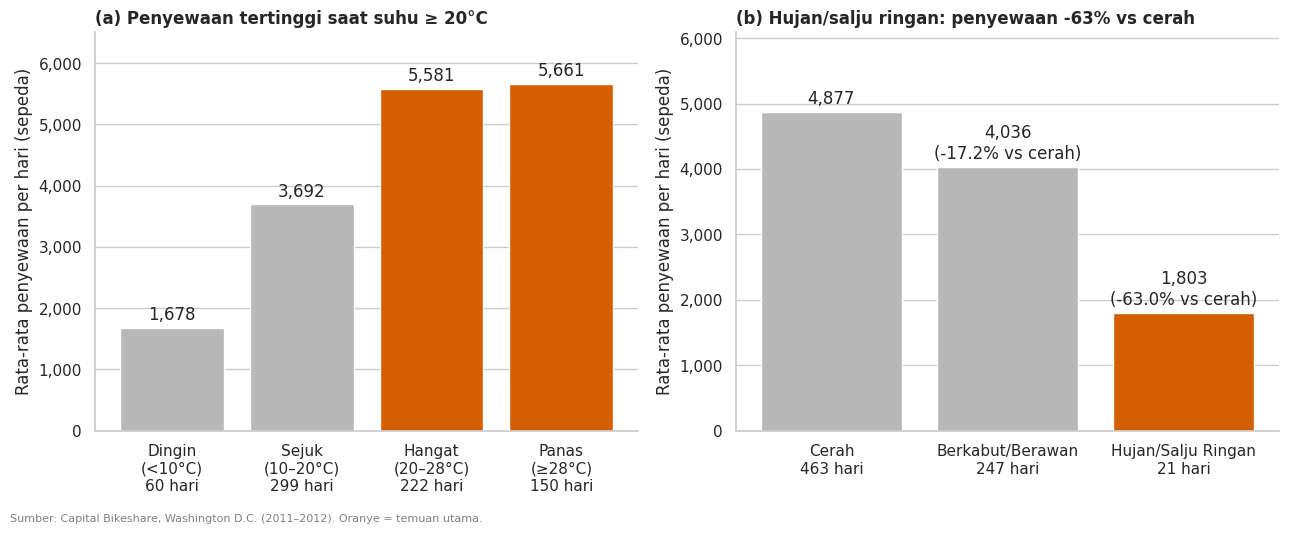

In [49]:
# Visualisasi 3: rata-rata penyewaan harian berdasarkan kategori suhu dan kondisi cuaca

# Buat 2 grafik berdampingan
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# (a) Kategori suhu: beri warna sorotan pada kategori yang nilainya dalam 5% dari nilai tertinggi
ax = axes[0]
temp_means = q2_temp['rata2_penyewaan']
colors = [COLOR_HIGHLIGHT if v >= 0.95 * temp_means.max() else COLOR_NEUTRAL for v in temp_means]
bars = ax.bar(range(len(temp_means)), temp_means.values, color=colors)
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in temp_means.values], padding=3)

# Atur label sumbu-x (nama kategori + jumlah hari), sumbu-y, dan judul
ax.set_xticks(range(len(temp_means)))
ax.set_xticklabels([str(lbl).replace(' (', '\n(') + f'\n{n} hari'
                    for lbl, n in zip(temp_means.index, q2_temp['jumlah_hari'])])
ax.set_ylim(0, temp_means.max() * 1.15)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_ylabel('Rata-rata penyewaan per hari (sepeda)')
ax.set_title('(a) Penyewaan tertinggi saat suhu ≥ 20°C', loc='left')

# (b) Kondisi cuaca: beri warna sorotan pada kondisi dengan penyewaan terendah
ax = axes[1]
w_means = q2_weather['rata2_penyewaan']
w_colors = [COLOR_HIGHLIGHT if v == w_means.min() else COLOR_NEUTRAL for v in w_means]
bars = ax.bar(range(len(w_means)), w_means.values, color=w_colors)

# Buat label batang: nilai rata-rata dan persentase perubahan dibanding cuaca cerah
w_labels = []
for cond, v in w_means.items():
    if cond == 'Cerah':
        w_labels.append(f'{v:,.0f}')
    else:
        pct = q2_weather.loc[cond, 'perubahan_vs_cerah_%']
        w_labels.append(f'{v:,.0f}\n({pct:+.1f}% vs cerah)')
ax.bar_label(bars, labels=w_labels, padding=3)

# Atur label sumbu-x, sumbu-y, dan judul
ax.set_xticks(range(len(w_means)))
ax.set_xticklabels([f'{cond}\n{n} hari' for cond, n in zip(w_means.index, q2_weather['jumlah_hari'])])
ax.set_ylim(0, w_means.max() * 1.25)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_ylabel('Rata-rata penyewaan per hari (sepeda)')
ax.set_title(f"(b) Hujan/salju ringan: penyewaan {q2_weather.iloc[-1]['perubahan_vs_cerah_%']:+.0f}% vs cerah",
             loc='left')

# Tambahkan sumber data
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare, Washington D.C. (2011–2012). Oranye = temuan utama.',
         fontsize=8, color='gray')

plt.tight_layout()
plt.show()

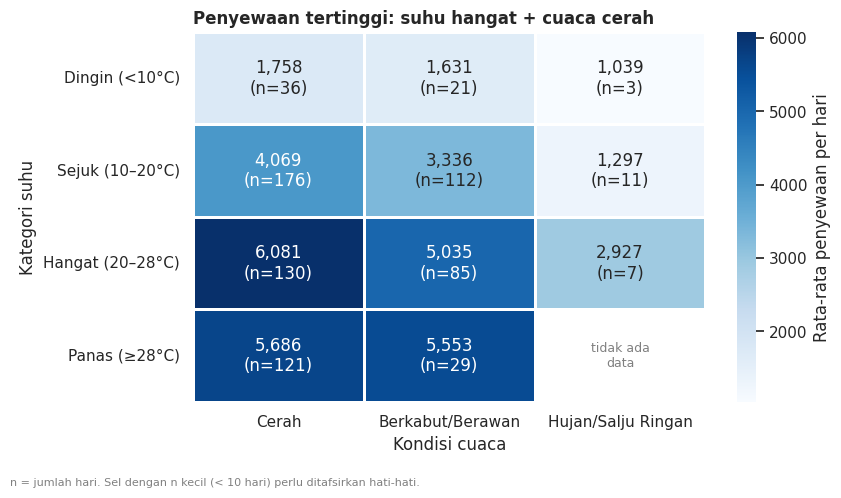

In [50]:
# Visualisasi 4: heatmap rata-rata penyewaan untuk kombinasi kategori suhu x kondisi cuaca

# Buat teks anotasi untuk setiap sel: rata-rata penyewaan dan jumlah hari (n)
annot = q2_cross.copy().astype(object)
for r in q2_cross.index:
    for c in q2_cross.columns:
        if pd.isnull(q2_cross.loc[r, c]):
            annot.loc[r, c] = ''
        else:
            annot.loc[r, c] = f'{q2_cross.loc[r, c]:,.0f}\n(n={int(q2_cross_n.loc[r, c])})'

# Buat heatmap
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.heatmap(q2_cross, annot=annot, fmt='', cmap='Blues', linewidths=1, linecolor='white',
            cbar_kws={'label': 'Rata-rata penyewaan per hari'}, ax=ax)

# Beri keterangan manual pada sel yang tidak memiliki data
for i, r in enumerate(q2_cross.index):
    for j, c in enumerate(q2_cross.columns):
        if pd.isnull(q2_cross.loc[r, c]):
            ax.text(j + 0.5, i + 0.5, 'tidak ada\ndata', ha='center', va='center', color='gray', fontsize=9)

# Atur judul dan label
ax.grid(False)
ax.set_xlabel('Kondisi cuaca')
ax.set_ylabel('Kategori suhu')
ax.set_title('Penyewaan tertinggi: suhu hangat + cuaca cerah', loc='left')
fig.text(0.01, -0.03, 'n = jumlah hari. Sel dengan n kecil (< 10 hari) perlu ditafsirkan hati-hati.',
         fontsize=8, color='gray')

plt.tight_layout()
plt.show()

**Insight:**

**Pertanyaan 1**
- Pengguna *casual* naik tajam saat hari libur: 607 → 1,371 sepeda/hari (selisih 765; +126%).
- Pengguna *registered* justru turun: 3,978 → 2,959 sepeda/hari (selisih -1,019; -26%). Kenaikan casual hanya mengimbangi sebagian penurunan registered, sehingga total harian turun tipis (-5.6%).
- Pola jam hari kerja: *registered* memiliki dua puncak komuter, pukul 08:00 (451) dan pukul 17:00 (467), sedangkan *casual* hanya memuncak pukul 17:00 (57).
- Pola jam hari libur: kedua jenis pengguna memuncak di siang hari — *casual* pukul 14:00 (140) dan *registered* pukul 12:00 (240), tanpa puncak komuter pagi.
- Pola ini konsisten dengan penggunaan *registered* untuk **komuter** dan *casual* untuk **rekreasi**. Kesimpulan ini bersifat dugaan karena dataset tidak mencatat tujuan perjalanan.

**Pertanyaan 2**
- Penyewaan tertinggi terjadi pada suhu ≥ 20°C: Panas 5,661 dan Hangat 5,581 sepeda/hari. Selisih keduanya hanya 1.4%, jadi keduanya dapat dianggap setara sebagai kondisi puncak. Pada suhu Dingin (<10°C) penyewaan jatuh ke 1,678 sepeda/hari (-70% dibanding Hangat).
- Cuaca cerah memberi rata-rata 4,877 sepeda/hari. Cuaca berkabut/berawan menurunkannya sebesar 17.2% dan hujan/salju ringan menurunkannya sebesar **63.0%** (rata-rata 1,803 sepeda/hari, berdasarkan 21 hari).
- Kombinasi terbaik adalah suhu Hangat + cuaca Cerah (6,081 sepeda/hari). Hujan/salju ringan pada suhu Hangat (2,927; n=7 hari) masih lebih rendah daripada suhu Sejuk + Cerah (4,069), yang mengindikasikan bahwa cuaca buruk menekan penyewaan lebih kuat daripada suhu yang sedikit lebih rendah (tetap perlu hati-hati karena jumlah hari hujan sedikit).
- Hari dengan penyewaan terendah adalah 29 Oktober 2012 (22 sepeda; cuaca hujan/salju ringan). Tanggal ini diduga berkaitan dengan Badai Sandy yang melanda pesisir timur AS, yang juga disebut dalam dokumentasi dataset sebagai salah satu kejadian penting.

**Prinsip desain dan integritas yang diterapkan pada seluruh visualisasi:**
- **Integritas data:** sumbu-y grafik batang selalu dimulai dari 0 sehingga tinggi batang sebanding dengan nilainya; nilai asli ditampilkan sebagai label; jumlah hari (n) dicantumkan agar pembaca tahu seberapa kuat datanya; tidak ada pemotongan sumbu, efek 3D, ataupun pemilihan rentang data yang menyesatkan; sumber data dan definisi *Hari Libur* dicantumkan pada grafik.
- **Kejelasan pesan:** judul grafik berisi temuan utama (bukan sekadar nama variabel); warna sorotan (oranye tua) hanya dipakai untuk temuan utama, sedangkan elemen pendukung berwarna abu-abu.
- **Konsistensi:** warna yang sama selalu berarti hal yang sama (oranye = *casual*, biru = *registered*) dan dipilih dari palet yang ramah buta warna; panel hari kerja dan hari libur memakai skala sumbu-y yang sama agar dapat dibandingkan langsung.
- **Minim gangguan visual:** hanya garis bantu horizontal, tanpa garis tepi atas/kanan; label sumbu lengkap dengan satuan; heatmap memakai satu warna bertingkat agar intensitas mudah dibaca.

## Analisis Lanjutan (Opsional)

Dua teknik analisis lanjutan (tanpa machine learning) digunakan pada proyek ini:

1. **Binning suhu** (`pd.cut`, sudah diterapkan pada bagian EDA & Pertanyaan 2). **Tujuan:** mengubah suhu kontinu menjadi 4 kategori (Dingin, Sejuk, Hangat, Panas) agar pengaruh suhu terhadap penyewaan dapat dibandingkan antar-kelompok dan langsung diterjemahkan menjadi aturan operasional.
2. **Manual grouping jam operasional** (di bawah ini). **Tujuan:** merangkum 24 jam ke dalam 5 periode berdasarkan pemahaman domain — Dini Hari (00–05), Pagi (06–09), Siang (10–15), Sore (16–19), dan Malam (20–23) — sehingga tim operasional dapat menentukan *kapan* harus menambah sepeda, melakukan *rebalancing*, atau menjadwalkan perawatan.

In [51]:
# Manual grouping: kelompokkan jam (0-23) menjadi 5 periode operasional

# Tentukan label periode dan batas jamnya (pd.cut memakai batas atas yang inklusif)
hour_labels = ['Dini Hari (00–05)', 'Pagi (06–09)', 'Siang (10–15)', 'Sore (16–19)', 'Malam (20–23)']
hour_df['hour_group'] = pd.cut(hour_df['hour'], bins=[-1, 5, 9, 15, 19, 23], labels=hour_labels)

# Cek jumlah baris pada setiap periode
hour_df['hour_group'].value_counts().sort_index()

,count
hour_group,
Dini Hari (00–05),4386
Pagi (06–09),2924
Siang (10–15),4386
Sore (16–19),2924
Malam (20–23),2924


In [52]:
# Menghitung rata-rata penyewaan per jam pada setiap periode, tipe hari, dan jenis pengguna

hourgroup_avg = hour_df.groupby(['day_type', 'hour_group'], observed=True)[['casual', 'registered']].mean()
hourgroup_avg.round(1)

casual  registered
day_type   hour_group                           
Hari Kerja Dini Hari (00–05)     2.6        13.3
           Pagi (06–09)         15.6       260.0
           Siang (10–15)        40.6       138.0
           Sore (16–19)         49.0       364.5
           Malam (20–23)        22.1       143.0
Hari Libur Dini Hari (00–05)     8.3        34.1
           Pagi (06–09)         19.5        65.4
           Siang (10–15)       120.8       218.2
           Sore (16–19)         97.4       199.3
           Malam (20–23)        32.4        96.8

In [53]:
# Menghitung sebaran (%) penyewaan setiap jenis pengguna ke dalam 5 periode

# Jumlahkan penyewaan pada setiap periode
hourgroup_sum = hour_df.groupby(['day_type', 'hour_group'], observed=True)[['casual', 'registered']].sum()

# Bagi dengan total pada tipe hari yang sama, lalu kalikan 100
hourgroup_share = hourgroup_sum.div(hourgroup_sum.groupby(level=0).transform('sum')) * 100
hourgroup_share.round(1)

casual  registered
day_type   hour_group                           
Hari Kerja Dini Hari (00–05)     2.6         2.0
           Pagi (06–09)         10.3        26.1
           Siang (10–15)        40.2        20.8
           Sore (16–19)         32.3        36.6
           Malam (20–23)        14.6        14.4
Hari Libur Dini Hari (00–05)     3.6         6.9
           Pagi (06–09)          5.7         8.8
           Siang (10–15)        52.9        44.2
           Sore (16–19)         28.4        26.9
           Malam (20–23)         9.4        13.1

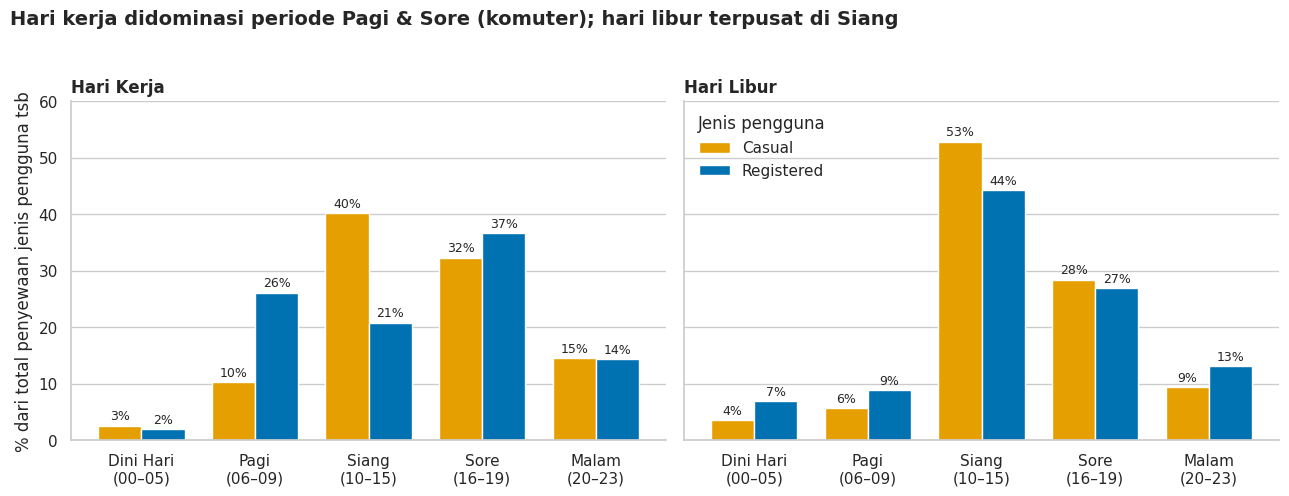

In [54]:
# Visualisasi 5: sebaran penyewaan per periode operasional

# Buat 2 grafik berdampingan (hari kerja dan hari libur)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
x = np.arange(len(hour_labels))

for ax, day_type in zip(axes, ['Hari Kerja', 'Hari Libur']):
    # Ambil sebaran periode pada tipe hari tersebut
    share = hourgroup_share.loc[day_type].reindex(hour_labels)

    # Buat bar chart berdampingan untuk casual dan registered
    bars_c = ax.bar(x - 0.19, share['casual'], width=0.38, color=COLOR_CASUAL, label='Casual')
    bars_r = ax.bar(x + 0.19, share['registered'], width=0.38, color=COLOR_REGISTERED, label='Registered')
    ax.bar_label(bars_c, labels=[f'{v:.0f}%' for v in share['casual']], padding=2, fontsize=9)
    ax.bar_label(bars_r, labels=[f'{v:.0f}%' for v in share['registered']], padding=2, fontsize=9)

    # Atur label sumbu-x dan judul
    ax.set_xticks(x)
    ax.set_xticklabels([label.replace(' (', '\n(') for label in hour_labels])
    ax.set_title(day_type, loc='left')
    ax.set_ylim(0, 60)

# Atur label sumbu-y, legend, dan judul utama
axes[0].set_ylabel('% dari total penyewaan jenis pengguna tsb')
axes[1].legend(title='Jenis pengguna', frameon=False, loc='upper left')
fig.suptitle('Hari kerja didominasi periode Pagi & Sore (komuter); hari libur terpusat di Siang',
             x=0.01, ha='left', fontsize=14, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

In [55]:
# Menyimpan data bersih ke folder dashboard untuk dipakai oleh Streamlit

# Buat folder dashboard jika belum ada
os.makedirs('dashboard', exist_ok=True)

# Simpan day_df dan hour_df ke file csv
day_df.to_csv('dashboard/main_data.csv', index=False)
hour_df.to_csv('dashboard/hour_data.csv', index=False)

# Cek ukuran data yang disimpan
print('main_data.csv :', day_df.shape)
print('hour_data.csv :', hour_df.shape)

main_data.csv : (731, 17)
hour_data.csv : (17544, 19)


**Insight:**
- Pada hari kerja, periode Pagi (06–09) dan Sore (16–19) — hanya 8 dari 24 jam — menyumbang 62.8% penyewaan *registered*. Ini adalah jendela komuter yang paling kritis untuk ketersediaan sepeda.
- Pada hari libur, periode Siang (10–15) menjadi pusat aktivitas: 52.9% penyewaan *casual* dan 44.2% penyewaan *registered*.
- Dini Hari (00–05) hanya menyumbang 2.0–6.9% penyewaan *registered* dan paling banyak 3.6% penyewaan *casual*, sehingga menjadi waktu paling aman untuk perawatan dan *rebalancing* armada.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama 2011–2012, rata-rata penyewaan harian pengguna *casual* pada hari libur lebih tinggi 765 sepeda (+126%; 607 → 1,371), sedangkan pengguna *registered* lebih rendah 1,019 sepeda (-26%; 3,978 → 2,959). Puncak penyewaan *registered* di hari kerja terjadi pukul 08:00 (451) dan 17:00 (467) (konsisten dengan pola komuter), sedangkan di hari libur puncak *casual* pukul 14:00 (140) dan *registered* pukul 12:00 (240) (konsisten dengan pola rekreasi).
- **Conclusion pertanyaan 2:** Penyewaan harian tertinggi terjadi pada suhu ≥ 20°C (Hangat 5,581 dan Panas 5,661 sepeda/hari) dengan kombinasi terbaik Hangat + Cerah (6,081 sepeda/hari), sedangkan suhu Dingin (<10°C) hanya 1,678 sepeda/hari. Dibanding cuaca cerah (4,877), hujan/salju ringan menurunkan penyewaan sebesar 63.0% dan cuaca berkabut/berawan sebesar 17.2%.
- **Catatan keterbatasan:** data hanya mencakup dua tahun di satu kota, dan jumlah hari hujan/salju ringan sedikit (21 hari) sehingga estimasi pada kondisi tersebut kurang stabil.

**Rekomendasi Action Item:**
- **Prioritaskan ketersediaan sepeda di jam komuter hari kerja.** Lakukan *rebalancing* sebelum pukul 07:00 dan sebelum pukul 16:00 dan pastikan stok di area perkantoran/transit pada 06:00–09:00 dan 16:00–19:00, karena periode ini menyumbang 62.8% penyewaan *registered*.
- **Pindahkan fokus ke area rekreasi dan jam siang pada hari libur.** Tambahkan sepeda di lokasi wisata/taman pada 10:00–17:00 (puncak *casual* pukul 14:00), dan jalankan promo *day-pass* atau konversi ke keanggotaan pada akhir pekan karena pengguna *casual* naik 126% dan porsinya mencapai 31.7% dari total.
- **Jadwalkan perawatan armada pada dini hari (00:00–05:00) dan pada hari bersuhu dingin atau hujan.** Dini hari hanya menyumbang 2.0–6.9% penyewaan *registered* dan paling banyak 3.6% penyewaan *casual*, sedangkan pada suhu <10°C penyewaan hanya 1,678 sepeda/hari (-70% dibanding suhu Hangat).
- **Gunakan prakiraan cuaca untuk menyesuaikan kapasitas.** Saat diprakirakan hujan/salju ringan (penurunan 63%) kurangi alokasi sepeda dan tunda event/promosi; saat hangat dan cerah (≥ 20°C) siapkan kapasitas maksimum dan perbanyak promosi.